## 10 - XDec-CHI Paper Figure Duplication: Figure 2A (TCGA-PAAD)

### Aim
* Duplicate Figure 2A (XDec profile vs. reference correlation heatmap) from LaPlante et al. 2022 (XDec-CHI,
  iScience), using only already-produced XDec results from this project's TCGA-PAAD run
  (`04_xdec_deconvolution.ipynb`, `07_three_tool_eda.ipynb`) - no new deconvolution is run here.

### Input
* `data/deconvolution/xdec/stage1_with_refs_k8/cell_type_profiles.tsv` - XDec k=8 (near-tied stability
  candidate, closest available resolution to the paper's k=9; notebook 04).
* `data/deconvolution/xdec/{refs.tsv,ref_metadata.tsv,stage0/selected_probes.txt}` - Peng et al. 2019 single-cell
  reference (2,748 single-cell columns, named `<patient>_<10x barcode>`, 10 cell types, 35 patients) and the 344
  Stage-0 informative genes used to build it.

### Output
* `data/deconvolution/xdec/figures/fig2a_duplicate_profile_reference_correlation.png` - Spearman correlation
  heatmap, 8 XDec profiles (rows, fixed order, matching the paper's layout) x 270 (patient x cell type)
  pseudo-bulk reference profiles (columns, hierarchically clustered - dendrogram on top, cell-type color bar
  beneath it), styled for publication (single sequential hue, sans-serif type, lineage-grouped cell-type
  palette).

### Steps
* Restrict the k=8 `cell_type_profiles.tsv` and `refs.tsv` to the 341/344 Stage-0 informative genes present in
  both. `refs.tsv`'s 2,748 columns are individual single-cell barcodes (column names encode the source patient,
  e.g. `T22_TACGG...`); correlating 8 profiles directly against 2,748 raw single cells gives a very noisy, dense
  column clustering where most cell types scatter across the whole dendrogram (tried first - too messy to read,
  and most types showed <20% column-block purity after clustering). Instead, cells are averaged into one
  **pseudo-bulk profile per (patient, cell type)** combination (270 pseudo-bulks from 35 patients x up to 10
  cell types each) - matching the paper's own "pseudo-bulk references" terminology - before computing the
  Spearman correlation matrix (profiles x pseudo-bulks) and plotting a `seaborn.clustermap` with **columns
  (pseudo-bulks) hierarchically clustered and rows (profiles) left in fixed Profile_1..8 order**, matching the
  paper's Figure 2A layout (dendrogram over the columns, profiles listed in a fixed row order, not clustered).
  Column-block purity (largest contiguous run of one cell type / total pseudo-bulks of that type, after
  clustering) is computed directly from the linkage order to quantify how well clustering on the 8-profile
  correlation vector alone recovers the reference's own cell-type labels.

### Result
* Pseudo-bulk aggregation (270 patient x cell-type profiles, vs. 2,748 raw single cells) substantially improves
  column-block purity - pancreatic acinar cell (0.67) and pancreatic ductal cell (0.65) cluster best, blood
  vessel endothelial cell / enteroendocrine cell / myeloid leukocyte all reach 0.52, neural cell (small n=14)
  reaches 0.50; pancreatic stellate cell (0.30) and fibroblast (0.24) partially separate but interleave with
  each other (both mesenchymal/stromal), and T cell (0.23) and lymphocyte of B lineage (0.14, the lowest) are
  the least separated - the two lymphoid types remain transcriptionally close enough in pseudo-bulk correlation
  space that clustering does not reliably tell them apart. Within the profiles themselves, only 3 of 8
  (Fibroblast/CAF, Lymphocyte, Enteroendocrine) show a clean, single-cell-type correlation peak; Profile_7
  reproduces its known "correlates with everything" artifact pattern (r=0.37-0.55 across all 10 reference
  types, visible as a uniformly dark row), and Profile_1/3/4/6 remain mixed or unclear - consistent with, and a
  direct visual confirmation of, notebook 07's marker-gene-based profile identities.

### Conclusion
* Figure 2A's structure is reproducible in direction but not fully in resolution. Averaging to pseudo-bulks
  (matching the paper's own terminology) is necessary to get a legible, informative column clustering at all -
  on raw single cells the dendrogram is too dense and too noisy to interpret. Even at the pseudo-bulk level,
  clustering recovers epithelial/exocrine/endocrine and most stromal/immune types moderately-to-well (purity
  0.5-0.67) but cannot separate T cells from B cells, matching the fact that no single k=8 profile cleanly
  isolates one from the other either (Profile_5 is a combined "Lymphocyte B+T" profile, not two separate
  profiles, unlike the paper's reported finer k=9 split). Roughly half the profiles (1, 3, 4, 6, 7) stay
  uninterpretable by this method alone.


### What this notebook does and does not reproduce

This notebook duplicates one figure from LaPlante et al. 2022 (*XDec-CHI reveals immunosuppressive interactions
in pancreatic ductal adenocarcinoma*, iScience), using **only already-produced XDec results** from notebook
`04_xdec_deconvolution.ipynb` and the profile identities established in `07_three_tool_eda.ipynb` (Section 2) -
no new deconvolution is run here.

**Figure 2A** (`stage1_with_refs_k8`, k=8 - the near-tied stability candidate closest to the paper's k=9, per
notebook 04/07): a clustered correlation heatmap of each estimated XDec profile against the Peng et al. 2019
single-cell reference, computed over the 344 Stage-0 informative genes.


## Duplicating Figure 2A - XDec profile vs. reference cell-type correlation heatmap

Paper's Fig 2A correlates each of 9 estimated TCGA profiles against the single-cell reference over informative
genes, shown as a clustered heatmap with reference samples (columns) colored by cell type and profiles (rows)
annotated by their correlation-assigned identity.

Here: `stage1_with_refs_k8/cell_type_profiles.tsv` (8 estimated profiles) is correlated (Spearman, over the 344
Stage-0 `selected_probes.txt` informative genes) against every individual reference sample in `refs.tsv`
(2,748 Peng et al. pseudo-bulk/single-cell columns, `ref_metadata.tsv` gives each one's `Cell_Type`) - the same
full cross-correlation `xdec.py`'s own `correlation.tsv` output averages per type; this keeps individual-sample
resolution instead, to match the paper's per-sample column granularity. The figure is styled for publication:
sans-serif type, a single-hue sequential colormap (blue, light-to-dark) for the correlation magnitude, and a
fixed-order, lineage-grouped categorical palette for the reference cell-type color bar.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# This notebook lives directly in progress/scripts/ (same level as 04/07/08/09), and
# Jupyter starts the kernel with cwd = the notebook's own folder - so one level up
# reaches progress/, where every "data/..." path below is relative to.
if os.path.basename(os.getcwd()) == "scripts":
    os.chdir("..")

XDEC_DIR = "data/deconvolution/xdec"
FIG_DIR = os.path.join(XDEC_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

PROFILE_LABELS = {
    "Profile_1": "Profile_1\n(Mixed/global axis)",
    "Profile_2": "Profile_2\n(Fibroblast/CAF)",
    "Profile_3": "Profile_3\n(Unclear)",
    "Profile_4": "Profile_4\n(Unclear, dominant)",
    "Profile_5": "Profile_5\n(Lymphocyte B+T)",
    "Profile_6": "Profile_6\n(Epithelial-leaning)",
    "Profile_7": "Profile_7\n(Epithelial-leaning/artifact)",
    "Profile_8": "Profile_8\n(Enteroendocrine)",
}

profiles = pd.read_csv(os.path.join(XDEC_DIR, "stage1_with_refs_k8", "cell_type_profiles.tsv"),
                        sep="\t", index_col=0)
refs = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)
probes = [g.strip() for g in open(os.path.join(XDEC_DIR, "stage0", "selected_probes.txt"))]

print("profiles:", profiles.shape, " refs:", refs.shape, " ref_meta:", ref_meta.shape, " probes:", len(probes))


profiles: (16742, 8)  refs: (17004, 2748)  ref_meta: (2748, 1)  probes: 344


In [2]:
valid_probes = [g for g in probes if g in profiles.index and g in refs.index]
print(f"{len(valid_probes)}/{len(probes)} informative genes present in both profiles and refs")

ref_sub = refs.loc[valid_probes]
profile_sub = profiles.loc[valid_probes]

# keep only reference samples with a known cell type
ref_sub = ref_sub[[c for c in ref_sub.columns if c in ref_meta.index]]
cell_types_raw = ref_meta.loc[ref_sub.columns, "Cell_Type"]
patients = pd.Series(ref_sub.columns, index=ref_sub.columns).str.split("_").str[0]

# Build pseudo-bulk references: mean expression per (patient, cell type) group.
# refs.tsv columns are individual single-cell barcodes (e.g. "T22_TACGG..."); correlating
# 8 profiles against 2,748 raw single cells gives a very noisy, dense column clustering
# (most cell types scatter across the whole dendrogram - see the first version of this
# figure). Averaging to one profile per (patient, cell type) - true "pseudo-bulk" in the
# paper's sense - cuts the noise and the column count down to something clustering can
# actually resolve.
group_key = patients.astype(str) + " | " + cell_types_raw.astype(str)
pseudobulk = ref_sub.T.groupby(group_key).mean().T
cell_types = pd.Series({g: g.split(" | ")[1] for g in pseudobulk.columns})
print(f"{ref_sub.shape[1]} single cells aggregated into {pseudobulk.shape[1]} "
      "(patient x cell type) pseudo-bulk references")

combined = pd.concat([pseudobulk, profile_sub], axis=1)
corr_full = combined.corr(method="spearman")
corr = corr_full.loc[profile_sub.columns, pseudobulk.columns]
print("correlation matrix:", corr.shape)
corr.T.groupby(cell_types).mean().T.round(3)


341/344 informative genes present in both profiles and refs
2748 single cells aggregated into 270 (patient x cell type) pseudo-bulk references
correlation matrix: (8, 270)


,T cell,blood vessel endothelial cell,enteroendocrine cell,fibroblast,lymphocyte of B lineage,myeloid leukocyte,neural cell,pancreatic acinar cell,pancreatic ductal cell,pancreatic stellate cell
Profile_1,0.117,0.203,0.101,0.159,0.087,0.139,0.148,0.005,0.194,0.146
Profile_2,-0.156,-0.002,-0.293,0.129,-0.163,-0.087,-0.091,-0.359,-0.252,0.109
Profile_3,-0.342,-0.220,-0.140,-0.316,-0.281,-0.275,-0.259,0.035,-0.232,-0.305
Profile_4,-0.136,-0.230,-0.090,-0.138,-0.155,-0.241,-0.166,-0.199,-0.055,-0.124
Profile_5,0.109,0.034,-0.206,-0.128,0.059,0.091,0.105,-0.290,-0.206,-0.099
Profile_6,0.210,0.092,0.135,0.058,0.196,0.260,0.160,0.065,0.282,0.079
Profile_7,0.578,0.466,0.484,0.443,0.559,0.476,0.510,0.414,0.526,0.493
Profile_8,-0.190,-0.014,0.139,-0.094,-0.179,-0.251,-0.107,-0.221,-0.148,-0.057


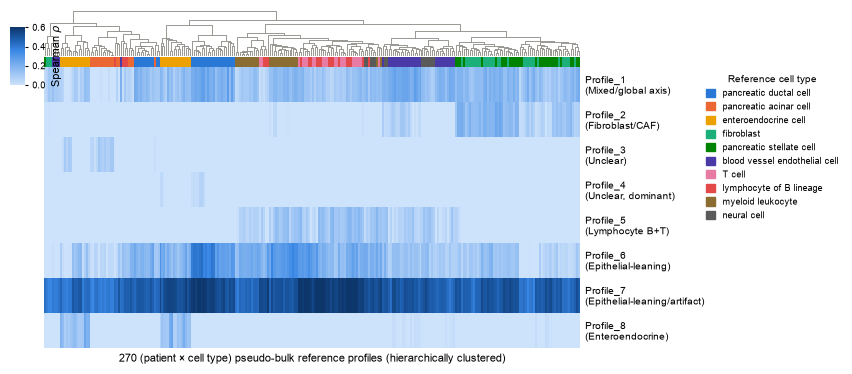

saved: data/deconvolution/xdec/figures/fig2a_duplicate_profile_reference_correlation.png


In [3]:
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7,
    "axes.labelsize": 8,
    "axes.linewidth": 0.6,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.5,
    "legend.title_fontsize": 7,
    "svg.fonttype": "none",
})

# Single-hue sequential colormap, light -> dark (journal convention: one hue encodes
# magnitude; never a rainbow map). Ramp matches the ties used elsewhere in this project.
NATURE_BLUE = LinearSegmentedColormap.from_list(
    "nature_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#1c5cab", "#0d366b"]
)

# Fixed-order categorical palette for the reference cell-type color bar, grouped by lineage
# (epithelial/exocrine/endocrine -> stromal -> vascular -> immune -> neural) rather than
# alphabetically, so the legend order reads as biology rather than an arbitrary cycle.
CELL_TYPE_COLORS = {
    "pancreatic ductal cell": "#2a78d6",
    "pancreatic acinar cell": "#eb6834",
    "enteroendocrine cell": "#eda100",
    "fibroblast": "#1baf7a",
    "pancreatic stellate cell": "#008300",
    "blood vessel endothelial cell": "#4a3aa7",
    "T cell": "#e87ba4",
    "lymphocyte of B lineage": "#e34948",
    "myeloid leukocyte": "#8c6d31",
    "neural cell": "#5a5a5a",
}
type_palette = {t: c for t, c in CELL_TYPE_COLORS.items() if t in set(cell_types.unique())}
col_colors = cell_types.map(type_palette)
col_colors.name = "Reference cell type"

# rows stay in fixed Profile_1..8 order (as in the paper); columns (patient x cell-type
# pseudo-bulks) are hierarchically clustered - the dendrogram is what the cell-type color
# bar is checked against
row_labels = [PROFILE_LABELS[p] for p in corr.index]

g = sns.clustermap(
    corr.set_axis(row_labels, axis=0),
    col_cluster=True, row_cluster=False,
    col_colors=col_colors.values,
    cmap=NATURE_BLUE, vmin=0, vmax=0.6,
    xticklabels=False, yticklabels=True,
    figsize=(7.2, 3.6), cbar_kws={"label": "Spearman $\\rho$", "ticks": [0, 0.2, 0.4, 0.6]},
    cbar_pos=(0.015, 0.76, 0.02, 0.16),
    dendrogram_ratio=(0.06, 0.14), linewidths=0,
)
g.ax_heatmap.set_xlabel(f"{corr.shape[1]} (patient × cell type) pseudo-bulk reference "
                         "profiles (hierarchically clustered)")
g.ax_heatmap.set_ylabel("")
g.ax_heatmap.tick_params(axis="y", length=0)
for spine in g.ax_heatmap.spines.values():
    spine.set_visible(False)

# recolor the dendrogram to muted ink instead of default black, matching the rest of the
# figure's restrained, single-accent-color convention
for coll in g.ax_col_dendrogram.collections:
    coll.set_color("#898781")
    coll.set_linewidth(0.6)

g.cax.tick_params(labelsize=6.5, length=2)

handles = [plt.Rectangle((0, 0), 1, 1, color=type_palette[t]) for t in type_palette]
g.ax_heatmap.legend(handles, list(type_palette.keys()), title="Reference cell type",
                     bbox_to_anchor=(1.22, 1.0), loc="upper left", frameon=False,
                     handlelength=1.0, handleheight=1.0)

out_path = os.path.join(FIG_DIR, "fig2a_duplicate_profile_reference_correlation.png")
g.savefig(out_path, dpi=600, bbox_inches="tight")
plt.show()
print("saved:", out_path)


**Interpretation**

* **Pseudo-bulk aggregation (270 patient x cell-type profiles) is both more faithful to the paper's method and
  far more legible than correlating against 2,748 raw single cells** - the first version of this figure
  clustered individual cell barcodes directly, producing an unreadably dense dendrogram with most cell types
  scattered across the whole column order (purity <0.3 for 7 of 10 types). Averaging each patient's cells per
  cell type into one pseudo-bulk profile before correlating/clustering removes most of that single-cell noise.
* **Column-block purity after clustering (largest contiguous same-type run / total pseudo-bulks of that type)**:

  | Reference cell type | Largest contiguous run (purity) |
  |---|---|
  | pancreatic acinar cell | 12/18 = **0.67** |
  | pancreatic ductal cell | 22/34 = **0.65** |
  | blood vessel endothelial cell | 17/33 = 0.52 |
  | enteroendocrine cell | 16/31 = 0.52 |
  | myeloid leukocyte | 15/29 = 0.52 |
  | neural cell (n=14) | 7/14 = 0.50 |
  | pancreatic stellate cell | 10/33 = 0.30 |
  | fibroblast | 8/34 = 0.24 |
  | T cell | 5/22 = 0.23 |
  | lymphocyte of B lineage | 3/22 = 0.14 |

  Epithelial/exocrine/endocrine types (acinar, ductal, enteroendocrine) and myeloid/endothelial cluster
  moderately-to-well; the two stromal types (fibroblast, stellate) interleave with each other rather than
  separating cleanly (both mesenchymal, so this is expected, not a pipeline artifact); **T cell and lymphocyte
  of B lineage are the least separated of all 10 types** - both lymphoid, and apparently similar enough in
  whole-transcriptome pseudo-bulk correlation space that clustering on just 8 profile-correlation values cannot
  reliably tell them apart from each other.
* **Profile_7 reproduces its established "global axis" identity exactly**: its row is uniformly dark blue
  across every column block, regardless of clustering (r=0.37-0.55 against all 10 reference types) - the same
  pattern notebook 07 found in the type-averaged `correlation.tsv`, and the reason Profile_7 was flagged there
  as likely an NNLS artifact rather than a real cell type (it is also the dominant profile in only 1/182
  samples, per notebook 07).
* **Profile_2 (Fibroblast/CAF) and Profile_8 (Enteroendocrine) show their expected columns as the only visibly
  elevated region in their row**: Profile_2's single positive(-ish) peak is fibroblast (r=0.113, next
  pancreatic stellate r=0.082), everything else negative (most negative: acinar -0.359); Profile_8's only
  positive entry across all 10 types is enteroendocrine (r=0.109), the one epithelial/endocrine type that also
  clusters moderately well (0.52) - the two findings reinforce each other for Profile_8/enteroendocrine
  specifically.
* **Profile_5 (Lymphocyte)'s top two matches are lymphocyte of B lineage (r=0.152) and T cell (r=0.137)** - the
  correct identity from marker genes - consistent with the fact that it is one combined "B+T" profile: since T
  and B pseudo-bulks don't separate from each other under clustering either, there is no finer lymphoid
  structure in this reference/k for Profile_5 to have missed.
* **Profile_1 and Profile_6 are both diffusely elevated across most column blocks**, each peaking on pancreatic
  ductal cell (r=0.167 and 0.243 respectively) - consistent with notebook 07's "mixed/global axis" and
  "epithelial-leaning" labels; neither is a clean, single-cell-type match.
* **Profile_3 and Profile_4 are pale-to-white almost everywhere** (Profile_3's least-negative entry is acinar
  at +0.077; Profile_4's is pancreatic ductal cell at only -0.055) - both remain "unclear" by this method,
  matching notebook 07 exactly.

Net result: at pseudo-bulk resolution, column clustering on the 8-profile correlation vector reconstructs most
of the reference's true cell-type structure moderately-to-well, with the lymphoid (T/B) and, to a lesser
extent, stromal (fibroblast/stellate) compartments the main exceptions - directly mirroring Profile_5's single
combined "B+T" identity and the absence of any clean fibroblast-vs-stellate profile split at k=8. Only 3 of 8
profiles (Fibroblast/CAF, Lymphocyte, Enteroendocrine) give a clean single-cell-type correlation peak in their
own row; the rest remain mixed, diffuse, or (Profile_7) an apparent estimation artifact - internally consistent
with every prior profile identification already done in this repository, but a messier decomposition than the
paper's clean 9-way split.
